# Configuración básica de una red neuronal convolucional (PyTorch)

Una vez hemos estudiado los conceptos básicos de las redes convolucionales, como las capas convolucionales y de pooling, es hora de construir nuestra propia red. Como ejemplo usaremos la base de datos Fashion MNIST.

En este notebook usaremos **PyTorch**. A diferencia de otras librerías que ocultan el ciclo de entrenamiento dentro de una función (`fit`), en PyTorch lo escribimos nosotros mismos. Esto requiere unas pocas líneas más, pero nos permite ver exactamente qué ocurre en cada paso del aprendizaje.

## Etapa 1: Se carga la base de datos.

In [39]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import matplotlib.pyplot as plt

Si hay una GPU disponible, la usaremos para acelerar el entrenamiento; de lo contrario, se usa la CPU. Tanto el modelo como los datos deben estar en el mismo dispositivo.

In [40]:
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Dispositivo:", device)

Dispositivo: cuda


Cargamos Fashion MNIST con `torchvision`. La transformación `ToTensor()` convierte cada imagen en un tensor y **normaliza** los valores de los píxeles del rango $[0, 255]$ al intervalo $[0, 1]$.

In [41]:
train_data = datasets.FashionMNIST(root="data", train=True, download=True,
                                  transform=transforms.ToTensor())
test_data = datasets.FashionMNIST(root="data", train=False, download=True,
                                 transform=transforms.ToTensor())

In [42]:
# El conjunto de entrenamiento está compuesto por 60000 imágenes de tamaño 28x28
print(train_data.data.shape)

torch.Size([60000, 28, 28])


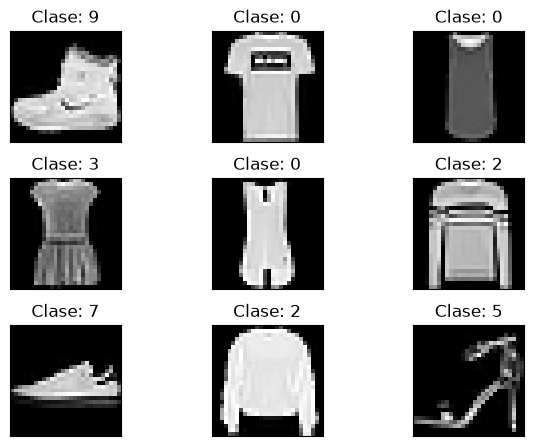

In [43]:
fig = plt.figure()
for i in range(9):
    plt.subplot(3, 3, i + 1)
    plt.tight_layout()
    plt.imshow(train_data.data[i], cmap="gray", interpolation="none")
    plt.title("Clase: {}".format(train_data.targets[i].item()))
    plt.xticks([])
    plt.yticks([])
plt.show()

## Etapa 2: Se procesan las imágenes para que sean compatibles con la red convolucional.

Las imágenes ya fueron normalizadas al intervalo $[0, 1]$ por `ToTensor()`. Además, `ToTensor()` agrega una dimensión para los **canales** de la imagen. Como usamos imágenes en escala de grises, hay un solo canal. Las imágenes a color se representan usualmente con tres canales RGB (rojo, verde y azul). Para profundizar más acerca de las representaciones de las imágenes a color y en escala de grises, los invito a leer la siguiente publicación [Enlace.](https://towardsdatascience.com/exploring-the-mnist-digits-dataset-7ff62631766a)

Veamos la forma de una imagen:

In [44]:
image, label = train_data[0]
print(image.shape)  # (canales, alto, ancho)
print(image.min().item(), image.max().item())

torch.Size([1, 28, 28])
0.0 1.0


**Una diferencia importante:** PyTorch ordena las dimensiones como `(canales, alto, ancho)`, mientras que otras librerías usan `(alto, ancho, canales)`. Con un minibatch, la forma completa es `(batch, canales, alto, ancho)`.

Ahora creamos los `DataLoader`, que se encargan de entregar los datos en **minibatches** de tamaño 32. En el conjunto de entrenamiento mezclamos (`shuffle=True`) los datos en cada época.

In [45]:
batch_size = 32
train_loader = DataLoader(train_data, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(test_data, batch_size=batch_size, shuffle=False)

images, labels = next(iter(train_loader))
print(images.shape)  # (batch, canales, alto, ancho)
print(labels.shape)

torch.Size([32, 1, 28, 28])
torch.Size([32])


## Etapa 3: Definición del modelo

Ahora, es momento de definir el modelo de redes convolucionales. Usualmente, las capas de pooling se alimentan de las salidas de las capas convolucionales. Así, se suele definir como una capa oculta al conjunto de una capa convolucional más una capa de pooling.

Para este ejemplo definimos una red simple compuesta por dos capas ocultas y una capa de salida de tipo densa (`nn.Linear`) con 10 unidades.

In [46]:
model = nn.Sequential(
    # La primera capa oculta se compone de una capa convolucional con 32 filtros,
    # cada uno con tamaño kernel_size=3x3. En PyTorch debemos indicar cuántos
    # canales tiene la entrada (in_channels=1, escala de grises) y cuántos
    # produce la capa (out_channels=32, uno por filtro). Con padding=0 (sin
    # relleno) y stride=1, la salida de la convolución será de tamaño 26x26x32.
    # Nótese que no definimos la cantidad de imágenes, pues esta dependerá del
    # tamaño del minibatch que usemos.
    nn.Conv2d(in_channels=1, out_channels=32, kernel_size=3, stride=1, padding=0),
    # La no linealidad ReLU es una capa aparte en PyTorch.
    nn.ReLU(),
    # Luego, el resultado pasa a través de una capa de Max Pooling que usa filtros
    # 2x2 y un paso de 2. De esta forma, la salida será de tamaño 13x13x32.
    nn.MaxPool2d(kernel_size=2, stride=2),

    # Definimos una nueva capa convolucional con 64 filtros. Ahora la entrada
    # tiene 32 canales (los que produjo la capa anterior). Una particularidad de
    # las redes convolucionales es que, mientras las imágenes se vuelven cada vez
    # más pequeñas por las operaciones de convolución y pooling, la cantidad de
    # filtros tiende a aumentar: aquí duplicamos de 32 a 64. Al final de la
    # convolución tendremos una salida de tamaño 11x11x64.
    nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3, stride=1, padding=0),
    nn.ReLU(),
    # Finalizamos esta capa oculta con un Max Pooling, que reduce la
    # representación a un tamaño de 5x5x64 (11/2 = 5.5, se redondea hacia abajo).
    nn.MaxPool2d(kernel_size=2, stride=2),

    # Las capas convolucionales funcionan como extractoras de características de
    # las imágenes. Luego, estas características se usan para cumplir con la tarea
    # de aprendizaje; en nuestro caso, clasificación en 10 clases. Para esto usamos
    # una capa de aplastamiento (Flatten), que convierte un arreglo de múltiples
    # dimensiones en uno de una sola dimensión. Como la entrada es de tamaño
    # 5x5x64, la salida tendrá 5*5*64 = 1600 unidades.
    nn.Flatten(),

    # Se aplica una capa de Dropout con el fin de prevenir el sobre-ajuste.
    nn.Dropout(0.5),

    # Finalmente se define la capa de salida: 10 neuronas, una por cada clase.
    # Observe que NO agregamos Softmax. La función de costo que usaremos
    # (CrossEntropyLoss) ya la incluye internamente, por lo que la red entrega
    # "logits" (puntajes sin normalizar).
    nn.Linear(in_features=5 * 5 * 64, out_features=10),
)
model = model.to(device)

Veamos un resumen del modelo. Podemos imprimirlo directamente y contar los parámetros entrenables:

In [47]:
print(model)

total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print("Total de parámetros entrenables:", total_params)

Sequential(
  (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1))
  (1): ReLU()
  (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1))
  (4): ReLU()
  (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (6): Flatten(start_dim=1, end_dim=-1)
  (7): Dropout(p=0.5, inplace=False)
  (8): Linear(in_features=1600, out_features=10, bias=True)
)
Total de parámetros entrenables: 34826


Para verificar los tamaños que calculamos a mano, pasemos un minibatch de ejemplo capa por capa:

In [48]:
x = images.to(device)
for layer in model:
    x = layer(x)
    print(f"{layer.__class__.__name__:10s} -> {tuple(x.shape)}")

Conv2d     -> (32, 32, 26, 26)
ReLU       -> (32, 32, 26, 26)
MaxPool2d  -> (32, 32, 13, 13)
Conv2d     -> (32, 64, 11, 11)
ReLU       -> (32, 64, 11, 11)
MaxPool2d  -> (32, 64, 5, 5)
Flatten    -> (32, 1600)
Dropout    -> (32, 1600)
Linear     -> (32, 10)


Los parámetros coinciden con lo esperado:

- Primera convolución: $(3 \times 3 \times 1 + 1) \times 32 = 320$
- Segunda convolución: $(3 \times 3 \times 32 + 1) \times 64 = 18496$
- Capa densa: $(1600 + 1) \times 10 = 16010$

Total: $34826$ parámetros.

# Etapa 4: Entrenamiento y evaluación del modelo

Entrenar una red consiste en repetir, minibatch tras minibatch, cinco pasos: `zero_grad`, forward, cálculo del costo, `backward` y `step`. Para no repetir ese código cada vez que queramos probar otra red, lo agrupamos en una **clase** `Trainer` con un método por cada tarea:

| Método | Qué hace |
|---|---|
| `__init__` | Guarda la red y crea la función de costo (`CrossEntropyLoss`, que incluye la Softmax) y el optimizador (`Adam`). |
| `train_epoch` | Recorre todos los minibatches de una época y actualiza los pesos. |
| `evaluate` | Mide costo y accuracy sobre un conjunto, sin entrenar. |
| `fit` | Repite `train_epoch` y `evaluate` durante varias épocas y guarda el historial. |
| `predict` | Devuelve la clase predicha para cada imagen. |

In [49]:
class Trainer:
    def __init__(self, model, lr=1e-3):
        self.model = model
        self.loss_fn = nn.CrossEntropyLoss()
        # El optimizador recibe los parámetros del modelo que debe actualizar
        self.optimizer = torch.optim.Adam(model.parameters(), lr=lr)
        self.history = {"loss": [], "accuracy": [], "val_loss": [], "val_accuracy": []}

    def train_epoch(self, loader):
        # Una época: recorre todos los minibatches y actualiza los pesos
        self.model.train()  # activa el Dropout
        total_loss, correct = 0.0, 0
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)

            # 1. Paso hacia adelante: predicciones y costo
            logits = self.model(images)
            loss = self.loss_fn(logits, labels)

            # 2. Paso hacia atrás: gradientes
            self.optimizer.zero_grad()  # borra los gradientes del minibatch anterior
            loss.backward()

            # 3. Se actualizan los parámetros
            self.optimizer.step()

            # Acumulamos ponderando por el tamaño del minibatch
            total_loss += loss.item() * images.shape[0]
            correct += (logits.argmax(dim=1) == labels).sum().item()
        return total_loss / len(loader.dataset), correct / len(loader.dataset)

    def evaluate(self, loader):
        # Mide el desempeño sin entrenar
        self.model.eval()  # desactiva el Dropout
        total_loss, correct = 0.0, 0
        with torch.no_grad():  # no necesitamos gradientes al evaluar
            for images, labels in loader:
                images, labels = images.to(device), labels.to(device)
                logits = self.model(images)
                total_loss += self.loss_fn(logits, labels).item() * images.shape[0]
                correct += (logits.argmax(dim=1) == labels).sum().item()
        return total_loss / len(loader.dataset), correct / len(loader.dataset)

    def fit(self, train_loader, val_loader, epochs=10):
        for epoch in range(epochs):
            loss, acc = self.train_epoch(train_loader)
            val_loss, val_acc = self.evaluate(val_loader)
            for key, value in zip(self.history, (loss, acc, val_loss, val_acc)):
                self.history[key].append(value)
            print(f"Época {epoch + 1}/{epochs} - loss: {loss:.4f} - accuracy: {acc:.4f} "
                  f"- val_loss: {val_loss:.4f} - val_accuracy: {val_acc:.4f}")

    def predict(self, images):
        # Devuelve la clase (0-9) predicha para cada imagen
        self.model.eval()
        with torch.no_grad():
            return self.model(images.to(device)).argmax(dim=1).cpu()

Con la clase definida, entrenar la red se reduce a crear el objeto y llamar a `fit`. Entrenamos con minibatches de tamaño 32 durante 10 épocas; al final de cada época se mide el rendimiento en el conjunto de prueba. Probar otro `lr` u otra arquitectura es cambiar un argumento.

In [50]:
trainer = Trainer(model, lr=1e-3)
trainer.fit(train_loader, test_loader, epochs=10)

Época 1/10 - loss: 0.5452 - accuracy: 0.8008 - val_loss: 0.4208 - val_accuracy: 0.8508
Época 2/10 - loss: 0.3972 - accuracy: 0.8564 - val_loss: 0.3431 - val_accuracy: 0.8788
Época 3/10 - loss: 0.3520 - accuracy: 0.8724 - val_loss: 0.3287 - val_accuracy: 0.8836
Época 4/10 - loss: 0.3303 - accuracy: 0.8796 - val_loss: 0.3128 - val_accuracy: 0.8903
Época 5/10 - loss: 0.3170 - accuracy: 0.8837 - val_loss: 0.2899 - val_accuracy: 0.8949
Época 6/10 - loss: 0.3054 - accuracy: 0.8885 - val_loss: 0.2989 - val_accuracy: 0.8926
Época 7/10 - loss: 0.2930 - accuracy: 0.8930 - val_loss: 0.2847 - val_accuracy: 0.8970
Época 8/10 - loss: 0.2875 - accuracy: 0.8945 - val_loss: 0.2860 - val_accuracy: 0.8946
Época 9/10 - loss: 0.2808 - accuracy: 0.8977 - val_loss: 0.2703 - val_accuracy: 0.9026
Época 10/10 - loss: 0.2764 - accuracy: 0.8991 - val_loss: 0.2702 - val_accuracy: 0.9011


Finalmente, se evalúa el rendimiento del modelo en el conjunto de prueba y se miran algunas predicciones.

In [51]:
test_loss, test_acc = trainer.evaluate(test_loader)
print("Test accuracy:", test_acc)

images, labels = next(iter(test_loader))
print("Predicciones:", trainer.predict(images[:10]).tolist())
print("Reales:      ", labels[:10].tolist())

Test accuracy: 0.9011
Predicciones: [9, 2, 1, 1, 6, 1, 4, 6, 5, 7]
Reales:       [9, 2, 1, 1, 6, 1, 4, 6, 5, 7]


Podemos visualizar la evolución del entrenamiento:

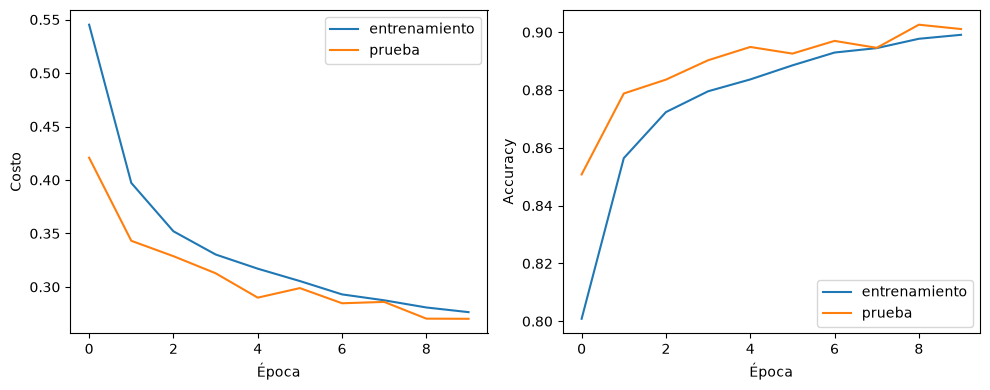

In [52]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(trainer.history["loss"], label="entrenamiento")
axes[0].plot(trainer.history["val_loss"], label="prueba")
axes[0].set_xlabel("Época")
axes[0].set_ylabel("Costo")
axes[0].legend()
axes[1].plot(trainer.history["accuracy"], label="entrenamiento")
axes[1].plot(trainer.history["val_accuracy"], label="prueba")
axes[1].set_xlabel("Época")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
plt.tight_layout()
plt.show()

## Etapa 5: Visualización de las predicciones

El accuracy nos dice cuántos aciertos hay, pero no **qué** predice la red. Veamos sus predicciones sobre imágenes del conjunto de prueba. Primero definimos los nombres de las 10 clases de Fashion MNIST (la red solo entrega números del 0 al 9).

In [53]:
class_names = ["Camiseta", "Pantalón", "Suéter", "Vestido", "Abrigo",
               "Sandalia", "Camisa", "Tenis", "Bolso", "Botín"]

Tomamos un minibatch de prueba y le pedimos a `trainer.predict` la clase de cada imagen. Si la predicción es correcta el título se muestra en **verde**; si no, en **rojo**.

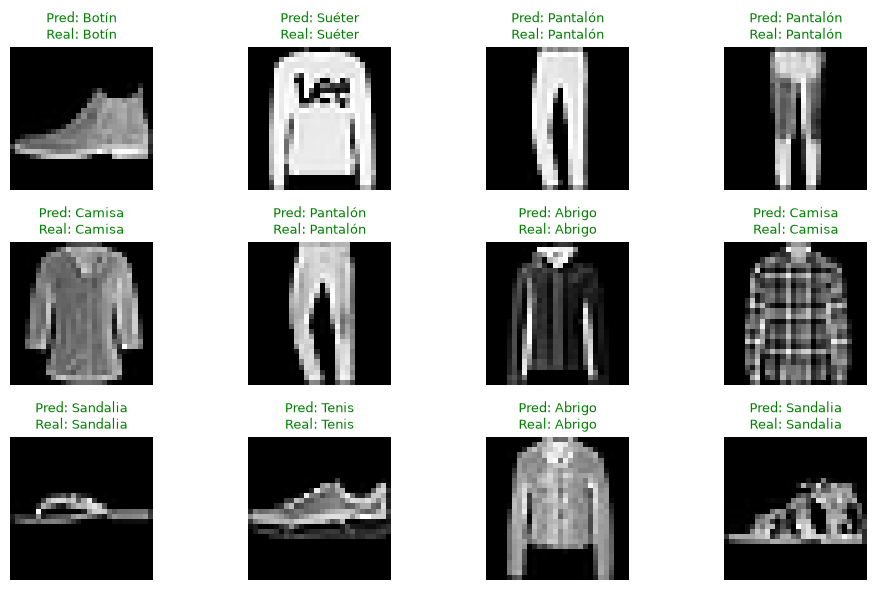

In [54]:
images, labels = next(iter(test_loader))
predictions = trainer.predict(images)

plt.figure(figsize=(10, 6))
for i in range(12):
    plt.subplot(3, 4, i + 1)
    plt.imshow(images[i].squeeze(), cmap="gray")  # squeeze quita la dimensión del canal
    correct = predictions[i] == labels[i]
    plt.title(f"Pred: {class_names[predictions[i]]}\nReal: {class_names[labels[i]]}",
              color="green" if correct else "red", fontsize=9)
    plt.axis("off")
plt.tight_layout()
plt.show()

Además de la clase, la red nos da qué tan segura está. Si aplicamos `softmax` a los *logits*, obtenemos probabilidades que suman 1. Veamos las de una imagen:

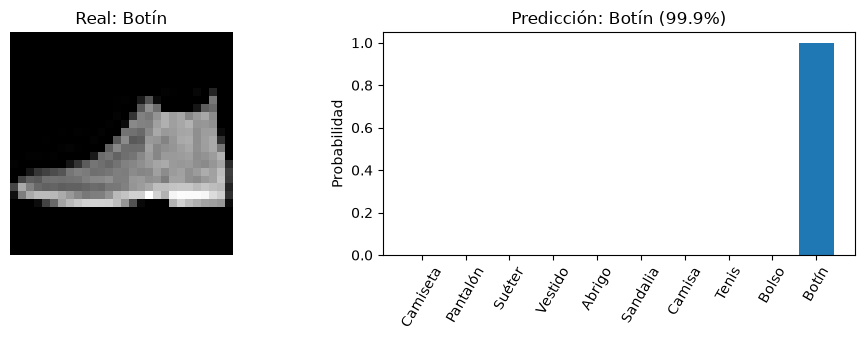

In [55]:
index = 0
model.eval()
with torch.no_grad():
    logits = model(images[index:index + 1].to(device))
probs = torch.softmax(logits, dim=1).squeeze().cpu()

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].imshow(images[index].squeeze(), cmap="gray")
axes[0].set_title(f"Real: {class_names[labels[index]]}")
axes[0].axis("off")
axes[1].bar(range(10), probs)
axes[1].set_xticks(range(10))
axes[1].set_xticklabels(class_names, rotation=60)
axes[1].set_ylabel("Probabilidad")
axes[1].set_title(f"Predicción: {class_names[probs.argmax()]} ({probs.max():.1%})")
plt.tight_layout()
plt.show()

Finalmente, veamos las imágenes donde la red **se equivoca**. Muchas veces son prendas que también nos cuesta distinguir, como camisa, camiseta y suéter.

La red se equivocó en 989 de 10000 imágenes


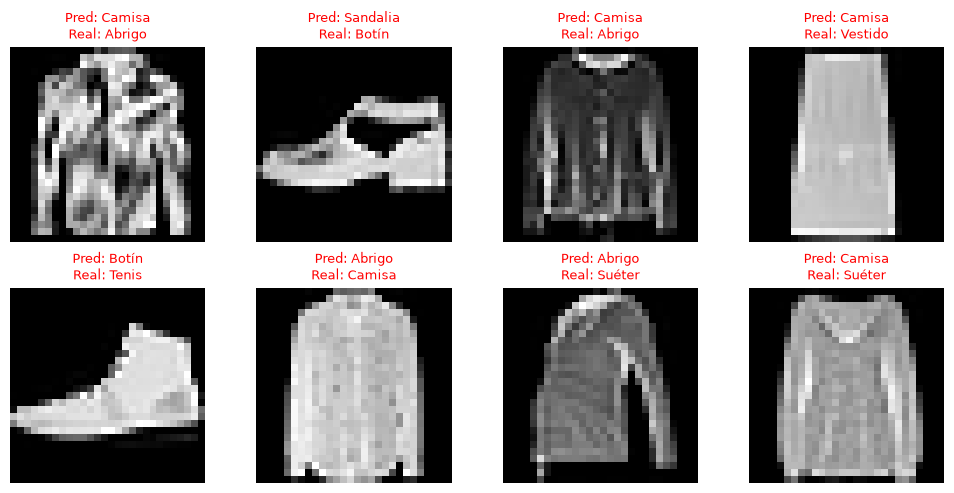

In [56]:
all_images, all_labels = test_data.data.unsqueeze(1).float() / 255, test_data.targets
all_predictions = trainer.predict(all_images)
wrong = (all_predictions != all_labels).nonzero().flatten()[:8]
print(f"La red se equivocó en {(all_predictions != all_labels).sum().item()} de {len(all_labels)} imágenes")

plt.figure(figsize=(10, 5))
for k, i in enumerate(wrong):
    plt.subplot(2, 4, k + 1)
    plt.imshow(all_images[i].squeeze(), cmap="gray")
    plt.title(f"Pred: {class_names[all_predictions[i]]}\nReal: {class_names[all_labels[i]]}",
              color="red", fontsize=9)
    plt.axis("off")
plt.tight_layout()
plt.show()

### Prueba con tus propias fotos

Ahora lo más interesante: **sube una foto de una prenda** (la tuya, de una tienda en línea, etc.) y la red intentará clasificarla al instante.

Pero la red solo conoce imágenes como las de Fashion MNIST: **28x28 píxeles, en escala de grises, con la prenda clara sobre fondo oscuro**. Por eso, antes de predecir, la foto pasa por un preprocesamiento:

1. Se convierte a escala de grises.
2. Se recorta al centro para que sea cuadrada.
3. Se reduce a 28x28 píxeles.
4. Se ajusta el contraste.
5. Si el fondo es claro (lo habitual en una foto), se **invierte**, para parecerse a las imágenes con las que se entrenó.

> Usa una foto con **una sola prenda, centrada y sobre fondo liso**. Esta celda usa `ipywidgets` (si no la tienes: `pip install ipywidgets`) y funciona en Jupyter y en VS Code.

In [57]:
import io
import numpy as np
import ipywidgets as widgets
from IPython.display import display
from PIL import Image, ImageOps


def preprocess_photo(photo):
    # Convierte una foto cualquiera en una imagen parecida a las de Fashion MNIST
    gray = photo.convert("L")                                   # 1. escala de grises
    side = min(gray.size)
    left, top = (gray.width - side) // 2, (gray.height - side) // 2
    gray = gray.crop((left, top, left + side, top + side))      # 2. recorte cuadrado
    gray = gray.resize((28, 28))                                # 3. tamaño 28x28
    gray = ImageOps.autocontrast(gray)                          # 4. contraste
    pixels = torch.from_numpy(np.array(gray)).float() / 255
    border = torch.cat([pixels[0], pixels[-1], pixels[:, 0], pixels[:, -1]])
    if border.mean() > 0.5:                                     # 5. fondo claro -> invertir
        pixels = 1 - pixels
    return pixels


def classify_photo(photo):
    # Devuelve la imagen procesada y las probabilidades de las 10 clases
    pixels = preprocess_photo(photo)
    trainer.model.eval()
    with torch.no_grad():
        logits = trainer.model(pixels.reshape(1, 1, 28, 28).to(device))
    return pixels, torch.softmax(logits, dim=1).squeeze().cpu()


def show_result(photo):
    pixels, probs = classify_photo(photo)
    pred = probs.argmax().item()
    fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), gridspec_kw={"width_ratios": [1, 1, 2]})
    axes[0].imshow(photo)
    axes[0].set_title("Tu foto")
    axes[0].axis("off")
    axes[1].imshow(pixels, cmap="gray")
    axes[1].set_title("Lo que ve la red (28x28)")
    axes[1].axis("off")
    bars = axes[2].bar(range(10), probs, color="lightgray")
    bars[pred].set_color("tab:blue")
    axes[2].set_xticks(range(10))
    axes[2].set_xticklabels(class_names, rotation=60)
    axes[2].set_ylim(0, 1)
    axes[2].set_ylabel("Probabilidad")
    axes[2].set_title(f"Predicción: {class_names[pred]} ({probs[pred]:.1%})")
    plt.tight_layout()
    plt.show()


uploader = widgets.FileUpload(accept="image/*", multiple=False, description="Subir foto")
result = widgets.Output()


def on_upload(change):
    files = uploader.value
    # Según la versión de ipywidgets, el valor es una tupla o un diccionario
    file = files[0] if isinstance(files, tuple) else list(files.values())[0]
    photo = Image.open(io.BytesIO(bytes(file["content"]))).convert("RGB")
    with result:
        result.clear_output(wait=True)
        show_result(photo)


uploader.observe(on_upload, names="value")
display(uploader, result)

FileUpload(value=(), accept='image/*', description='Subir foto')

Output()

Prueba con distintas prendas. Algunas preguntas para pensar:

- ¿Qué pasa si la foto tiene un fondo con mucho detalle, o si la prenda no está centrada?
- ¿Qué pasa con algo que **no** es una prenda, por ejemplo una taza? La red solo conoce 10 clases, así que siempre elegirá una de ellas, aunque sea con poca seguridad.
- ¿Se confunde más con camisa, camiseta y suéter, como vimos en los errores de arriba?